# Shortest Path Lab · Single dataset folder edition
### Load your CSV → choose a route → inspect the search → verify the answer

**Run all cells in order.** The final cell prompts you for a dataset, algorithm, source, goal and scope.
No dataset is selected automatically. Place this notebook in your project folder beside `Datasets`. It reads CSVs directly from that folder; no generator import or generator filename is required.
The saved dataset is never modified.

The simulator reads the existing **Datasets** folder in your project. All CSVs sit directly inside it.
The simulator saves its result images automatically in **Images**, also beside the generator.
Each PNG is named after the selected CSV, algorithm, source and goal.
Use generator menu **3 · Import existing datasets** to copy older CSVs into that folder.
Rerun the simulation prompt cell after generation or import; it refreshes the file list each time.
The import preserves the current sectioned CSV format and skips duplicate content.

Works with the current generator format: **Nodes / Edges / Expected Distances**.
IDs start at 1. Johnson inputs have no coordinates; A* inputs do.

Dependencies: `numpy`, `matplotlib`, `IPython` (included with Jupyter). Optional: `ipywidgets` for the playback slider.
If needed, run `%pip install numpy matplotlib ipywidgets` in a separate cell and restart the kernel.
The text prompts and static dashboards work without widgets.

In [7]:
from pathlib import Path
import csv, io, math, heapq, time, html
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import display, HTML, clear_output
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

plt.rcParams.update({'figure.figsize': (10, 6), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
# Use the project's existing Datasets directory, independent of generator filename.
from pathlib import Path

PROJECT_DIR = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / 'Datasets').is_dir()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        'Datasets folder not found. Open this notebook from your project folder, '
        'or set PROJECT_DIR = Path(r"/full/path/to/Graph_Routing_Project").'
    )
DATASET_ROOT = (PROJECT_DIR / 'Datasets').resolve()
IMAGES_DIR = PROJECT_DIR / 'Images'
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
print('Reading datasets from:', DATASET_ROOT)
print('Saving images to:', IMAGES_DIR)

DEMO = """# Nodes
node_id
1
2
3
4

# Edges
source_node,target_node,weight
1,2,-2
2,3,-1
3,1,4
1,4,3
3,4,1

# Expected Distances
source_node,target_node,expected_distance
1,1,0
1,2,-2
1,3,-3
1,4,-2
2,1,3
2,2,0
2,3,-1
2,4,0
3,1,4
3,2,2
3,3,0
3,4,1
4,1,inf
4,2,inf
4,3,inf
4,4,0
"""
print('Ready. Dataset folder:', DATASET_ROOT.resolve())

Reading datasets from: /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/Datasets
Saving images to: /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/Images
Ready. Dataset folder: /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/Datasets


## 1 · Read the graph
Expected distances are kept separate from the adjacency list and are **never used to guide a search**.
For large CSVs the reader retains only the first 20,000 expected rows in memory; verification
streams the file again, so saved expectations are not silently discarded.

In [8]:
HEADERS = {
    '# Nodes': [['node_id'], ['node_id', 'x_coordinate', 'y_coordinate']],
    '# Edges': [['source_node', 'target_node', 'weight']],
    '# Expected Distances': [['source_node', 'target_node', 'expected_distance']],
}

def rows_from(text=None, path=None):
    handle = io.StringIO(text) if path is None else Path(path).open(newline='', encoding='utf-8-sig')
    with handle:
        section = None
        header = None
        seen = set()
        for line, cells in enumerate(csv.reader(handle), 1):
            if not cells or all(not x.strip() for x in cells):
                continue
            cells = [x.strip() for x in cells]
            if cells[0].startswith('#'):
                if section is not None and header is None:
                    raise ValueError('Missing column header before line ' + str(line))
                if len(cells) != 1 or cells[0] not in HEADERS or cells[0] in seen:
                    raise ValueError('Unknown/duplicate section on line ' + str(line))
                section, header = cells[0], None
                seen.add(section)
                continue
            if section is None:
                raise ValueError('Expected # Nodes or # Edges before data.')
            if header is None:
                if cells not in HEADERS[section]:
                    raise ValueError('Incorrect column header in ' + section)
                header = cells
                continue
            if len(cells) != len(header):
                raise ValueError('Incorrect column count on line ' + str(line))
            yield section, dict(zip(header, cells))
        if not {'# Nodes', '# Edges'}.issubset(seen) or header is None:
            raise ValueError('Missing nodes, edges, or column header.')

def read_graph(path=None):
    path = None if path is None else Path(path).expanduser().resolve()
    g = {'nodes': {}, 'edges': [], 'expected': {}, 'expected_count': 0,
         'path': path, 'text': DEMO if path is None else None}
    seen_edges = set()
    for section, row in rows_from(g['text'], path):
        if section == '# Nodes':
            u = int(row['node_id'])
            if u < 1 or u in g['nodes']:
                raise ValueError('Node IDs must be positive and unique.')
            xy = (float(row['x_coordinate']), float(row['y_coordinate'])) if 'x_coordinate' in row else None
            if xy is not None and not all(math.isfinite(x) for x in xy):
                raise ValueError('Coordinates must be finite.')
            g['nodes'][u] = xy
        elif section == '# Edges':
            u, v, w = int(row['source_node']), int(row['target_node']), float(row['weight'])
            if (u,v) in seen_edges or not math.isfinite(w):
                raise ValueError('Duplicate edge or nonfinite edge weight.')
            seen_edges.add((u,v)); g['edges'].append((u,v,w))
        elif row['expected_distance']:
            u,v = int(row['source_node']),int(row['target_node'])
            d = float(row['expected_distance'])
            if math.isnan(d): raise ValueError('Expected distance cannot be NaN.')
            g['expected_count'] += 1
            if len(g['expected']) < 20000:
                g['expected'][u,v] = d
    if not g['nodes']: raise ValueError('The graph has no nodes.')
    g['adj'] = {u: [] for u in g['nodes']}
    for u,v,w in g['edges']:
        if u not in g['nodes'] or v not in g['nodes']:
            raise ValueError('An edge references a missing node.')
        g['adj'][u].append((v,w))
    g['spatial'] = all(xy is not None for xy in g['nodes'].values())
    return g

def expected_rows(g):
    for section,row in rows_from(g['text'],g['path']):
        if section == '# Expected Distances' and row['expected_distance']:
            yield int(row['source_node']), int(row['target_node']), float(row['expected_distance'])

## 2 · Algorithms with traces
Johnson first computes Bellman–Ford potentials from an implicit super-source, then runs
Dijkstra on reweighted edges. A negative cycle stops execution cleanly.

For A*, the notebook checks whether Manhattan or Euclidean distance is consistent with **every edge**.
If neither is safe, it uses zero. The priority is `(f, h, node_id)`, preferring smaller h on ties.
Counts below are **unique settled nodes, including the goal**; stale heap entries are excluded.

In [9]:
class NegativeCycleError(ValueError):
    pass

def bellman_potentials(g):
    h = {u: 0.0 for u in g['nodes']}  # Equivalent to zero-cost super-source edges.
    frames = [dict(h)] if len(h) <= 200 else []
    for pass_index in range(len(h)):
        changed = False
        for u,v,w in g['edges']:
            if h[u] + w < h[v]:
                h[v] = h[u] + w
                changed = True
        if frames: frames.append(dict(h))
        if not changed: return h,frames
        if pass_index == len(h)-1:
            raise NegativeCycleError('Negative Cycle Detected')
    return h,frames

def search(adj, start, goal=None, estimate=None, trace=False):
    estimate = estimate or (lambda u: 0.0)
    distance = {u: math.inf for u in adj}; distance[start] = 0.0
    parent = {}; settled = set(); events = []
    h0 = estimate(start)
    heap = [(h0,h0,start,0.0)]
    while heap:
        _,h,u,cost = heapq.heappop(heap)
        if u in settled or cost != distance[u]: continue
        settled.add(u); opened = []
        if u != goal:
            for v,w in adj[u]:
                candidate = cost+w
                if candidate < distance[v]:
                    distance[v] = candidate; parent[v] = u
                    hv = estimate(v)
                    heapq.heappush(heap,(candidate+hv,hv,v,candidate))
                    opened.append(v)
        if trace: events.append({'node':u,'g':cost,'h':h,'opened':opened})
        if u == goal: break
    return {'distance':distance,'parent':parent,'events':events,'settled':len(settled)}

def reconstruct(parent, start, goal):
    if start == goal: return [start]
    if goal not in parent: return []
    path = [goal]
    while path[-1] != start:
        path.append(parent[path[-1]])
        if len(path) > len(parent)+1: raise ValueError('Invalid parent cycle.')
    return path[::-1]

def choose_heuristic(g,goal):
    if not g['spatial']: return (lambda u: 0.0),'zero (no coordinates)'
    manhattan_ok = euclidean_ok = True
    for u,v,w in g['edges']:
        x,y=g['nodes'][u]; xx,yy=g['nodes'][v]
        manhattan_ok &= abs(x-xx)+abs(y-yy) <= w
        euclidean_ok &= math.hypot(x-xx,y-yy) <= w
    gx,gy=g['nodes'][goal]
    if manhattan_ok:
        return lambda u: abs(g['nodes'][u][0]-gx)+abs(g['nodes'][u][1]-gy),'Manhattan'
    if euclidean_ok:
        return lambda u: math.hypot(g['nodes'][u][0]-gx,g['nodes'][u][1]-gy),'Euclidean'
    return (lambda u: 0.0),'zero (geometric estimates unsafe)'

def run_algorithm(g, algorithm, start, goal, full=False):
    if start not in g['nodes'] or goal not in g['nodes']:
        raise ValueError('Choose source and goal IDs present in the graph.')
    result={'algorithm':algorithm,'start':start,'goal':goal,'g':g}
    begin=time.perf_counter()
    if algorithm == 'Johnson':
        h,frames=bellman_potentials(g)
        adj={u:[] for u in g['nodes']}
        reweighted=[]
        for u,v,w in g['edges']:
            rw=w+h[u]-h[v]
            if rw < -1e-9: raise ValueError('Invalid negative reweighted edge.')
            rw=max(0.0,rw);adj[u].append((v,rw));reweighted.append((u,v,rw))
        if full and len(adj)>500:
            raise ValueError('Full all-pairs simulation is limited to 500 nodes; disable it for this graph.')
        sources=sorted(adj) if full else [start]
        distances={}; selected=None
        for s in sources:
            run=search(adj,s,trace=(s==start))
            distances[s]={t:d-h[s]+h[t] for t,d in run['distance'].items()}
            if s==start: selected=run
        result.update(selected,distances=distances,cost=distances[start][goal],potentials=h,
                      potential_frames=frames,reweighted=reweighted,
                      scope='all pairs' if full else 'selected source only',heuristic='none')
    else:
        if any(w<0 for _,_,w in g['edges']):
            raise ValueError('A* and Dijkstra require nonnegative edges. Select Johnson.')
        estimate,name=choose_heuristic(g,goal)
        run=search(g['adj'],start,goal,estimate,trace=True)
        result.update(run,cost=run['distance'][goal],heuristic=name,scope='selected pair only')
    result['seconds']=time.perf_counter()-begin
    result['route']=reconstruct(result['parent'],start,goal)
    if result['route']:
        weights={(u,v):w for u,v,w in g['edges']}
        actual=sum(weights[u,v] for u,v in zip(result['route'],result['route'][1:]))
        if not math.isclose(actual,result['cost'],rel_tol=1e-9,abs_tol=1e-9):
            raise AssertionError('Returned path cost does not match distance.')
    if algorithm=='A*':
        begin=time.perf_counter();baseline=search(g['adj'],start,goal)
        result['baseline_seconds']=time.perf_counter()-begin
        result['baseline']=baseline
        assert equal_distance(result['cost'],baseline['distance'][goal]), 'A* / Dijkstra distance mismatch'
    return result

def equal_distance(a,b):
    return a==b if math.isinf(a) or math.isinf(b) else math.isclose(a,b,rel_tol=1e-9,abs_tol=1e-9)

def verify(result):
    checked=0; mismatches=[]; skipped=0
    for s,t,expected in expected_rows(result['g']):
        if result['algorithm']=='Johnson' and s in result['distances']:
            actual=result['distances'][s].get(t,math.inf)
        elif result['algorithm']=='A*' and (s,t)==(result['start'],result['goal']):
            actual=result['cost']
        else:
            skipped+=1;continue
        checked+=1
        if not equal_distance(actual,expected):
            if len(mismatches)<10:mismatches.append((s,t,expected,actual))
    return checked,skipped,mismatches

## 3 · Visual dashboard and playback
The dashboard places the graph beside search status and shows **CSV expected** and **actual cost** separately.
The final route is green; the frontier is amber; settled nodes are blue; the current node has a purple ring.
Source and goal are labelled. Edge weights and arrows are shown for small graphs.

For large graphs, only background edges are sampled for readability; the algorithm uses every edge.
Johnson's display layout is generated here and is not treated as geometric input.

In [10]:
# Visual design and result inspection. No graph-layout package required.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.lines import Line2D

THEME = dict(bg='#F3F6FA', ink='#16243A', muted='#64748B', edge='#B8C6D8',
             node='#CBD5E1', frontier='#F5B942', settled='#3979C6', path='#139B78', current='#8B5CF6')
_LAYOUT_CACHE = {}

def positions(g):
    if g['spatial']: return g['nodes']
    key=id(g)
    if key in _LAYOUT_CACHE and _LAYOUT_CACHE[key][0] is g: return _LAYOUT_CACHE[key][1]
    ids=sorted(g['nodes']); n=len(ids)
    if n==1: return {ids[0]:(0.0,0.0)}
    xy=np.array([(math.cos(2*math.pi*i/n), math.sin(2*math.pi*i/n)) for i in range(n)],dtype=float)
    # Deterministic force layout for small graphs; coordinates are visualization only.
    if n<=150:
        lookup={u:i for i,u in enumerate(ids)}
        links=np.zeros((n,n))
        for u,v,_ in g['edges']:
            if u!=v: links[lookup[u],lookup[v]]=links[lookup[v],lookup[u]]=1
        ideal=math.sqrt(4/n)
        for iteration in range(80):
            delta=xy[:,None,:]-xy[None,:,:]
            lengths=np.maximum(np.linalg.norm(delta,axis=2),1e-4)
            np.fill_diagonal(lengths,np.inf)
            repulsion=(delta*(ideal**2/lengths**2)[:,:,None]).sum(axis=1)
            safe=np.where(np.isfinite(lengths),lengths,0)
            attraction=(delta*(links*safe/ideal)[:,:,None]).sum(axis=1)
            force=repulsion-attraction
            norm=np.maximum(np.linalg.norm(force,axis=1),1e-9)
            temperature=.08*(1-iteration/80)
            xy += force/norm[:,None]*np.minimum(norm,temperature)[:,None]
            xy-=xy.mean(axis=0)
        xy/=max(np.abs(xy).max(),1e-9)
    result=dict(zip(ids,map(tuple,xy)))
    _LAYOUT_CACHE.clear(); _LAYOUT_CACHE[key]=(g,result)
    return result

def selected_expectation(g,source,goal):
    for s,t,value in expected_rows(g):
        if (s,t)==(source,goal): return value
    return None

def format_distance(value):
    if value is None:return 'Not supplied'
    if value==math.inf:return '∞ (unreachable)'
    if value==-math.inf:return '−∞ (unbounded)'
    return f'{value:,.6g}'

def table(headers,rows):
    # Explicit cell colors prevent VS Code's dark theme from making text invisible.
    th=''.join(
        '<th style="padding:12px 16px;text-align:left;background:#16243a !important;'
        'color:#ffffff !important;font-size:15px;font-weight:700;border-bottom:2px solid #3979c6">'
        +html.escape(str(x))+'</th>' for x in headers)
    body=[]
    for index,row in enumerate(rows):
        background='#ffffff' if index % 2 == 0 else '#edf3fa'
        cells=''.join(
            '<td style="padding:11px 16px;text-align:left;'
            'background:'+background+' !important;color:#102138 !important;'
            'border-bottom:1px solid #cbd5e1;font-size:15px;font-weight:500;'
            'font-variant-numeric:tabular-nums">'+html.escape(str(value))+'</td>'
            for value in row)
        body.append('<tr style="background:'+background+' !important">'+cells+'</tr>')
    display(HTML(
        '<div style="overflow:auto;max-height:520px;border:1px solid #94a3b8;'
        'border-radius:10px;margin:14px 0;background:#ffffff !important;color:#102138 !important">'
        '<table style="border-collapse:collapse;background:#ffffff !important;'
        'color:#102138 !important;font-family:system-ui;width:100%">'
        '<thead><tr>'+th+'</tr></thead><tbody>'+''.join(body)+'</tbody></table></div>'))


def draw_graph(g,result=None,step=None,ax=None):
    if ax is None: _,ax=plt.subplots(figsize=(11,7),facecolor=THEME['bg'])
    ax.set_facecolor('white')
    pos=positions(g); ids=sorted(pos); n=len(ids)
    events=result['events'] if result else []
    k=len(events) if step is None else max(0,min(int(step),len(events)))
    settled={e['node'] for e in events[:k]}
    frontier={result['start']} if result else set()
    for event in events[:k]:frontier.update(event['opened'])
    frontier-=settled
    route=result['route'] if result and k==len(events) else []
    path_edges=set(zip(route,route[1:])); path_nodes=set(route)
    show_labels=n<=35 and len(g['edges'])<=100
    pairs={(u,v) for u,v,_ in g['edges']}
    if show_labels:
        for u,v,w in g['edges']:
            if u==v:continue
            a,b=np.array(pos[u]),np.array(pos[v]);rad=.18 if (v,u) in pairs else 0
            on_path=(u,v) in path_edges
            color=THEME['path'] if on_path else THEME['edge']
            arrow=FancyArrowPatch(a,b,arrowstyle='-|>',connectionstyle=f'arc3,rad={rad}',
                                 shrinkA=17,shrinkB=17,mutation_scale=15,
                                 linewidth=2.5 if on_path else 1.3,color=color,zorder=2)
            ax.add_patch(arrow)
            delta=b-a; middle=(a+b)/2 + rad*np.array([delta[1],-delta[0]])/2
            ax.text(*middle,f'{w:g}',ha='center',va='center',fontsize=9,color=THEME['ink'],
                    bbox=dict(boxstyle='round,pad=.22',facecolor='white',edgecolor='none',alpha=.96),zorder=8)
    else:
        stride=max(1,math.ceil(len(g['edges'])/2500))
        ax.add_collection(LineCollection([(pos[u],pos[v]) for u,v,_ in g['edges'][::stride]],
                                        colors=THEME['edge'],linewidths=.45,alpha=.18,zorder=1))
        if path_edges:
            ax.add_collection(LineCollection([(pos[u],pos[v]) for u,v in path_edges],
                                            colors=THEME['path'],linewidths=2.7,zorder=4))
    size=650 if n<=35 else 65 if n<=300 else 14 if n<=3000 else 6
    colors=[THEME['path'] if u in path_nodes else THEME['settled'] if u in settled else THEME['frontier'] if u in frontier else THEME['node'] for u in ids]
    xy=np.array([pos[u] for u in ids])
    ax.scatter(xy[:,0],xy[:,1],s=size,c=colors,edgecolors='white',linewidths=1 if n<=300 else .1,zorder=5)
    if n<=35:
        for u in ids:ax.text(*pos[u],str(u),ha='center',va='center',fontweight='bold',fontsize=11,color=THEME['ink'],zorder=7)
    if result:
        for u,label,color in [(result['start'],'START','#16243A'),(result['goal'],'GOAL',THEME['path'])]:
            ax.scatter(*pos[u],s=max(size*1.45,80),facecolors='none',edgecolors=color,linewidths=2,zorder=6)
            ax.annotate(label,xy=pos[u],xytext=(0,23 if label=='START' else -28),textcoords='offset points',
                        ha='center',fontsize=8,fontweight='bold',color=color,
                        bbox=dict(boxstyle='round,pad=.2',facecolor='white',edgecolor='none',alpha=.9),zorder=9)
    if k:
        ax.scatter(*pos[events[k-1]['node']],s=max(size*1.8,110),facecolors='none',edgecolors=THEME['current'],linewidths=2,zorder=6)
    ax.autoscale();ax.margins(.22);ax.set_aspect('equal');ax.set_axis_off()
    title='GRAPH VIEW' if not result else f'SEARCH TRACE  ·  step {k:,} / {len(events):,}'
    ax.set_title(title,loc='left',fontsize=11,fontweight='bold',color=THEME['ink'],pad=18)
    legend=[Line2D([0],[0],marker='o',linestyle='',color=THEME[key],label=label,markersize=7)
            for key,label in [('node','Unvisited'),('frontier','Frontier'),('settled','Settled'),('path','Shortest path')]]
    ax.legend(handles=legend,loc='lower center',bbox_to_anchor=(.5,-.04),ncol=4,frameon=False,fontsize=8)
    return ax

def dashboard(result,step=None):
    g=result['g']; events=result['events']; k=len(events) if step is None else int(step)
    if 'selected_expected' not in result:
        result['selected_expected']=selected_expectation(g,result['start'],result['goal'])
    expected=result['selected_expected']
    finished=k>=len(events)
    fig=plt.figure(figsize=(14,8.5),facecolor=THEME['bg'])
    fig.text(.04,.955,'SHORTEST PATH LAB',fontsize=11,fontweight='bold',color=THEME['muted'])
    fig.text(.04,.911,f'{result["algorithm"]}  /  {result["start"]} → {result["goal"]}',fontsize=25,fontweight='bold',color=THEME['ink'])
    label=g['path'].name if g['path'] else 'Built-in demonstration'
    fig.text(.96,.925,label,ha='right',fontsize=10,color=THEME['muted'])
    cards=[('VERTICES',f'{len(g["nodes"]):,}'),('DIRECTED EDGES',f'{len(g["edges"]):,}'),
           ('ACTUAL COST',format_distance(result['cost']) if finished else 'In progress'),('CSV EXPECTED',format_distance(expected))]
    for i,(heading,value) in enumerate(cards):
        x=.04+i*.235
        patch=FancyBboxPatch((x,.79),.22,.085,boxstyle='round,pad=.006,rounding_size=.012',transform=fig.transFigure,facecolor='white',edgecolor='#E2E8F0',zorder=0)
        fig.add_artist(patch);fig.text(x+.015,.846,heading,fontsize=8,color=THEME['muted'],fontweight='bold')
        fig.text(x+.015,.809,value,fontsize=15,color=THEME['ink'],fontweight='bold')
    grid=fig.add_gridspec(1,2,left=.04,right=.96,bottom=.09,top=.74,width_ratios=[2.3,1],wspace=.12)
    ax=fig.add_subplot(grid[0]);draw_graph(g,result,k,ax)
    side=fig.add_subplot(grid[1]);side.set_axis_off()
    def line(y,title,body,color=None):
        side.text(0,y,title,fontsize=9,fontweight='bold',color=THEME['muted'],transform=side.transAxes)
        side.text(0,y-.055,body,fontsize=12,color=color or THEME['ink'],transform=side.transAxes,va='top',wrap=True)
    if finished:
        status='NOT PROVIDED' if expected is None else 'PASS' if equal_distance(result['cost'],expected) else 'MISMATCH'
    else:status='IN PROGRESS'
    line(.98,'SELECTED PAIR VERIFICATION',status,THEME['path'] if status=='PASS' else '#B45309')
    line(.81,'SETTLED VERTICES',f'{k:,} / {len(g["nodes"]):,}')
    if k:
        e=events[k-1]
        line(.64,'CURRENT NODE',f'{e["node"]}   ·   g={e["g"]:g}, h={e["h"]:g}')
    line(.47,'SEARCH SCOPE',result['scope'])
    if result['algorithm']=='A*':
        line(.30,'HEURISTIC',result['heuristic'])
        if finished:
            reduction=100*(1-result['settled']/result['baseline']['settled'])
            line(.13,'VS DIJKSTRA',f'{reduction:.2f}% fewer settled nodes')
    else:
        line(.30,'JOHNSON TRACE','Dijkstra on reweighted edges')
        line(.13,'PATH COST','Original weights in result card')
    note='Large graph: background edges sampled; the algorithm uses every edge.' if len(g['nodes'])>35 or len(g['edges'])>100 else 'Arrowheads show direction. Edge labels are original weights.'
    fig.text(.04,.025,note,fontsize=9,color=THEME['muted'])
    return fig

def save_simulation_image(fig, g, algorithm, source, goal, suffix=''):
    """Save a PNG beside the generator, named for the selected dataset/run."""
    IMAGES_DIR.mkdir(parents=True, exist_ok=True)
    dataset_name = g['path'].stem if g['path'] else 'demo'
    label = f'{dataset_name}_{algorithm.replace("*", "star").lower()}_{source}_to_{goal}'
    if suffix: label += '_' + suffix
    label = ''.join('_' if char in '<>:"/\\|?*' else char for char in label)
    destination = IMAGES_DIR / (label + '.png')
    counter = 2
    while destination.exists():
        destination = IMAGES_DIR / f'{label}_{counter}.png'
        counter += 1
    fig.savefig(destination, dpi=160, bbox_inches='tight', facecolor=fig.get_facecolor())
    print('Image saved:', destination.resolve())
    return destination

def show_result(result):
    g=result['g']; result['selected_expected']=selected_expectation(g,result['start'],result['goal'])
    fig=dashboard(result)
    result['image_path']=save_simulation_image(fig,g,result['algorithm'],result['start'],result['goal'])
    plt.show()
    route=result['route']
    print('Shortest path:', ' → '.join(map(str,route)) if route else 'No route (unreachable).')
    print('Actual distance:',format_distance(result['cost']))
    print('CSV expected distance:',format_distance(result['selected_expected']))
    checked,skipped,errors=verify(result)
    print(f'CSV validation: {"FAIL" if errors else "PASS" if checked else "NO MATCHING EXPECTATION"} | {checked:,} checked | {skipped:,} outside this run’s scope')
    examples=[]
    for s,t,expected in expected_rows(g):
        actual=None
        if result['algorithm']=='Johnson' and s in result['distances']:actual=result['distances'][s].get(t,math.inf)
        elif (s,t)==(result['start'],result['goal']):actual=result['cost']
        if actual is not None:
            examples.append([s,t,format_distance(expected),format_distance(actual),'PASS' if equal_distance(actual,expected) else 'FAIL'])
        if len(examples)>=20:break
    if examples:table(['Source','Target','CSV expected','Computed','Check'],examples)
    else:print('This pair has no stored expected value. Select a pair from Expected Distances to compare it.')
    if errors:table(['Source','Target','Expected','Actual — mismatch'],errors)
    if result['algorithm']=='A*':
        b=result['baseline']
        fig,ax=plt.subplots(figsize=(9,2.8),facecolor=THEME['bg'])
        values=[result['settled'],b['settled']]
        bars=ax.barh(['A*','Dijkstra'],values,color=[THEME['path'],THEME['settled']],height=.45)
        ax.bar_label(bars,labels=[f'{v:,}' for v in values],padding=7)
        ax.set_xlim(0,max(values)*1.22);ax.invert_yaxis();ax.set_xlabel('Settled vertices (goal included)')
        ax.set_title('SEARCH EFFORT · same graph, source and goal',loc='left',fontsize=11,fontweight='bold')
        ax.spines[['top','right','left']].set_visible(False);ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
        fig.tight_layout()
        result['comparison_image_path']=save_simulation_image(fig,g,result['algorithm'],result['start'],result['goal'],'comparison')
        plt.show()
        print('A* / Dijkstra distance agreement: PASS')
        print(f'Illustrative time: A* {result["seconds"]:.6f}s; Dijkstra {result["baseline_seconds"]:.6f}s. A* includes trace/heuristic overhead.')
    elif len(g['nodes'])<=20:
        table(['Node','Bellman–Ford potential'],sorted(result['potentials'].items()))
        original={(u,v):w for u,v,w in g['edges']}
        table(['Source','Target','Original weight','Reweighted'],[(u,v,original[u,v],w) for u,v,w in result['reweighted']])
        ids=sorted(g['nodes'])
        table(['Source / target']+ids,[[s]+[format_distance(result['distances'][s][t]) for t in ids] for s in sorted(result['distances'])])

def step_player(result):
    if widgets is None:
        print('Playback widgets unavailable. Use the prompted step viewer in the next section.');return
    slider=widgets.IntSlider(value=0,min=0,max=len(result['events']),description='Step',continuous_update=False,layout=widgets.Layout(width='75%'))
    play=widgets.Play(value=0,min=0,max=len(result['events']),interval=2000)
    speed=widgets.Dropdown(options=[('1 second / step',1000),('2 seconds / step',2000),('3 seconds / step',3000),('5 seconds / step',5000)],value=2000,description='Speed')
    # Dropdown.value is not a frontend-synchronized trait; use Python observation.
    def change_speed(change):
        play.interval = int(change['new'])
    speed.observe(change_speed, names='value')
    previous=widgets.Button(description='Previous step',icon='step-backward')
    following=widgets.Button(description='Next step',icon='step-forward')
    previous.on_click(lambda _: setattr(slider,'value',max(0,slider.value-1)))
    following.on_click(lambda _: setattr(slider,'value',min(slider.max,slider.value+1)))
    widgets.jslink((play,'value'),(slider,'value'))
    out=widgets.Output()
    def update(_=None):
        with out:
            clear_output(wait=True);dashboard(result,slider.value);plt.show()
    slider.observe(update,names='value')
    print('Playback starts paused. Press Play to advance every 2 seconds; change Speed for a different delay.')
    print('Pause playback before using Previous step / Next step for manual inspection.')
    display(widgets.HBox([speed,previous,following]),widgets.HBox([play,slider]),out)
    update()
    if result['algorithm']=='Johnson' and result['potential_frames']:
        frames=result['potential_frames'];p=widgets.IntSlider(min=0,max=len(frames)-1,description='BF pass',continuous_update=False);box=widgets.Output()
        def show_pass(_=None):
            with box:
                clear_output(wait=True);table(['Node','Potential'],sorted(frames[p.value].items()))
        p.observe(show_pass,names='value');display(p,box);show_pass()

def simulate(g,algorithm,start,goal,full=False):
    try:result=run_algorithm(g,algorithm,start,goal,full)
    except NegativeCycleError:
        expected=selected_expectation(g,start,goal)
        display(HTML('<div style="background:#fff1f2;border-left:5px solid #e11d48;padding:18px;color:#881337;font:15px system-ui"><b>Negative Cycle Detected</b><br>Johnson stopped before reweighting. Finite all-pairs shortest paths do not exist.</div>'))
        print(f'CSV expectation for {start} → {goal}: {format_distance(expected)}')
        recorded=any(d==-math.inf for _,_,d in expected_rows(g))
        print('Negative-cycle expectation:', 'PASS — CSV contains unbounded distances' if recorded else 'Not supplied; cycle detected independently')
        ax=draw_graph(g)
        ax.set_title('Negative Cycle Detected — Johnson stopped',loc='left',color='#be123c')
        save_simulation_image(ax.figure,g,algorithm,start,goal,'negative_cycle')
        plt.show();return None
    show_result(result);step_player(result);return result

## 4 · Guided input functions
The next code cell defines the prompts. The **Start your simulation** cell below launches them.

1. Select a discovered CSV or type its full path.
2. Choose Johnson or A*. Invalid combinations are rejected with an explanation.
3. Enter source and goal IDs. The prompts show example pairs from Expected Distances.
4. Choose Johnson all-pairs or selected-source mode; A* checks one pair against Dijkstra.
5. Select **Simulate and show results**.

CSV verification checks the computed scope only. Pairs absent from Expected Distances are reported
as **Not supplied**, never as a pass. Full Johnson is capped at 500 nodes to avoid huge matrices.

In [11]:
# This is the main entry point. No file, source or goal is hardcoded.
def ask_choice(label,choices,default=None):
    print('\n'+label)
    for i,choice in enumerate(choices,1):print(f'  {i}. {choice}')
    while True:
        value=input('Enter choice'+(f' [{default}]' if default is not None else '')+': ').strip()
        if value.lower() in ('q','quit'):raise KeyboardInterrupt
        if not value and default is not None:value=str(default)
        if value.isdigit() and 1<=int(value)<=len(choices):return int(value)
        print('Choose one of the numbers shown, or Q to cancel.')

def ask_node(label,ids,default):
    while True:
        value=input(f'{label} [{default}]: ').strip()
        if value.lower() in ('q','quit'):raise KeyboardInterrupt
        try:
            node=int(value) if value else default
            if node in ids:return node
        except ValueError:pass
        print('Enter an existing node ID (IDs begin at 1), or Q to cancel.')

def choose_dataset():
    print('\nSTEP 1 / SELECT YOUR SAVED DATASET')
    print('Search folder:',DATASET_ROOT.resolve())
    paths=sorted(p for p in DATASET_ROOT.iterdir() if p.is_file() and p.suffix.lower() == '.csv')
    for i,path in enumerate(paths,1):print(f'  {i}. {path.relative_to(DATASET_ROOT)}')
    if not paths:
        print('No CSVs in the Datasets folder yet. Generate one, or use generator menu 3 to import old CSVs.')
    print('Enter a file number OR paste a CSV path.')
    print('D = explicit built-in demonstration; Q = cancel. Blank input selects nothing.')
    while True:
        value=input('Dataset: ').strip().strip('"').strip("'")
        if value.lower() in ('q','quit'):raise KeyboardInterrupt
        if not value:
            print('Please select a CSV or type D for the demo.');continue
        if value.lower()=='d':return read_graph()
        if value.isdigit() and 1<=int(value)<=len(paths):path=paths[int(value)-1]
        else:path=Path(value).expanduser()
        try:
            if path.suffix.lower()!='.csv':raise ValueError('Select a .csv file.')
            return read_graph(path)
        except (OSError,ValueError) as error:print('Could not load dataset:',error)

def guided_simulation():
    global LAST_GRAPH,LAST_RESULT
    LAST_GRAPH=LAST_RESULT=None
    try:
        g=choose_dataset();LAST_GRAPH=g
        ids=sorted(g['nodes']);negative=any(w<0 for _,_,w in g['edges'])
        print(f'\nLOADED: {len(ids):,} nodes | {len(g["edges"]):,} directed edges | {g["expected_count"]:,} expected-distance rows')
        print('Node IDs:',', '.join(map(str,ids[:20]))+(' …' if len(ids)>20 else ''))
        print('Coordinates:','present' if g['spatial'] else 'absent — visualization layout will be generated')
        print('Negative edge weights:','yes' if negative else 'no')
        recommended=1 if negative or not g['spatial'] else 2
        while True:
            choice=ask_choice('STEP 2 / CHOOSE THE ALGORITHM',['Johnson','A* search'],recommended)
            if choice==2 and negative:print('A* cannot run on negative edges. Choose Johnson for this dataset.');continue
            break
        algorithm='Johnson' if choice==1 else 'A*'
        print('\nSTEP 3 / SOURCE AND GOAL')
        examples=[]
        for s,t,w in expected_rows(g):
            if s!=t:examples.append((s,t,w))
            if len(examples)==5:break
        if examples:
            print('Example pairs with CSV expectations:')
            for s,t,w in examples:print(f'  {s} → {t}: {format_distance(w)}')
        default_start,default_goal=(examples[0][0],examples[0][1]) if examples else (ids[0],ids[-1])
        source=ask_node('Source node',ids,default_start)
        goal=ask_node('Goal node',ids,default_goal)
        expected=selected_expectation(g,source,goal)
        print('CSV expected for selected pair:',format_distance(expected))
        full=False
        if algorithm=='Johnson':
            if len(ids)<=500:
                full=ask_choice('STEP 4 / COMPUTATION SCOPE',['All source–target pairs','Only this source (partial Johnson run)'],1 if len(ids)<=200 else 2)==1
            else:print('\nSTEP 4 / Large graph: use Johnson preprocessing + selected-source Dijkstra. Full mode is capped at 500 nodes.')
        else:print('\nSTEP 4 / A* will compute the selected pair and compare it with Dijkstra.')
        if ask_choice('STEP 5 / RUN',['Simulate and show results','Cancel'],None)==2:
            print('Cancelled. No algorithm was run.');return None
        LAST_RESULT=simulate(g,algorithm,source,goal,full)
        return LAST_RESULT
    except (KeyboardInterrupt,EOFError):print('\nSimulation cancelled. Rerun this cell when ready.')
    except (ValueError,OSError,AssertionError) as error:print('Simulation could not complete:',error)

def prompted_step_viewer():
    if LAST_RESULT is None:
        print('Run a successful simulation first. Negative-cycle cases have no Dijkstra trace.');return
    total=len(LAST_RESULT['events'])
    print(f'Inspect steps 0–{total}. Enter Q to finish.')
    while True:
        value=input('Step number: ').strip()
        if value.lower() in ('q','quit',''):return
        try:
            step=int(value)
            if not 0<=step<=total:raise ValueError
        except ValueError:
            print('Enter a step within the shown range.');continue
        dashboard(LAST_RESULT,step);plt.show()

## 5 · Start your simulation
Run this cell and answer the prompts. Enter **Q** at any prompt to cancel.
Rerun this cell to choose another file or route. The built-in example is available only if you explicitly enter **D**.

After a successful run, use the playback slider. If widgets are unavailable, run
`prompted_step_viewer()` in a new cell: it asks which trace step you want to display.


STEP 1 / SELECT YOUR SAVED DATASET
Search folder: /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/Datasets
  1. 1.csv
Enter a file number OR paste a CSV path.
D = explicit built-in demonstration; Q = cancel. Blank input selects nothing.

LOADED: 3 nodes | 3 directed edges | 9 expected-distance rows
Node IDs: 1, 2, 3
Coordinates: present
Negative edge weights: no

STEP 2 / CHOOSE THE ALGORITHM
  1. Johnson
  2. A* search

STEP 3 / SOURCE AND GOAL
Example pairs with CSV expectations:
  1 → 2: 1,071
  1 → 3: 302
  2 → 1: 603
  2 → 3: 905
  3 → 1: 1,372
CSV expected for selected pair: 302

STEP 4 / A* will compute the selected pair and compare it with Dijkstra.

STEP 5 / RUN
  1. Simulate and show results
  2. Cancel
Image saved: /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/Images/1_astar_1_to_3.png


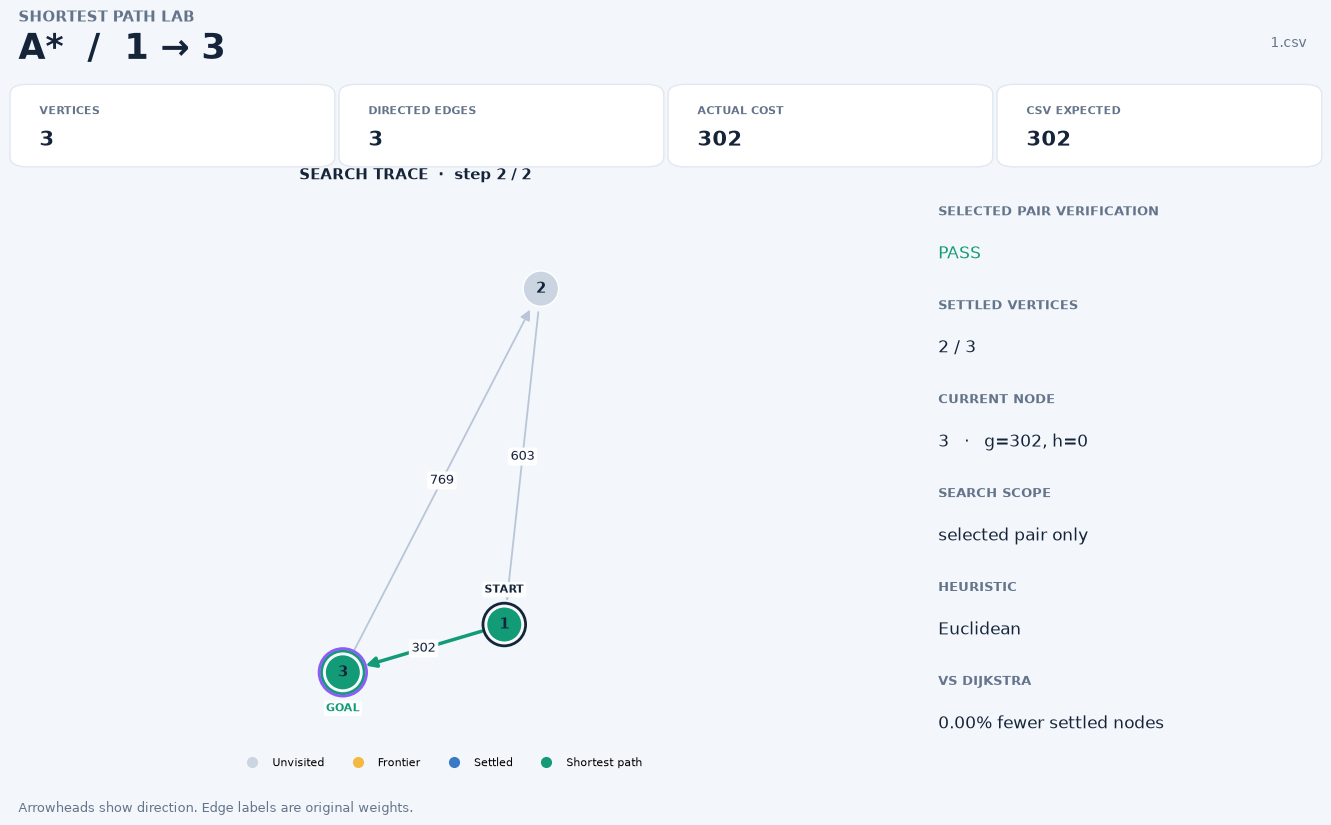

Shortest path: 1 → 3
Actual distance: 302
CSV expected distance: 302
CSV validation: PASS | 1 checked | 8 outside this run’s scope


Source,Target,CSV expected,Computed,Check
1,3,302,302,PASS


Image saved: /Users/aayush/Desktop/DSA/Graph_Routing_Project 8.19.08 PM/Images/1_astar_1_to_3_comparison.png


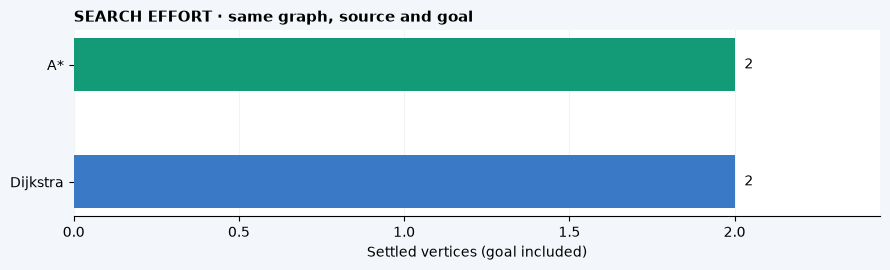

A* / Dijkstra distance agreement: PASS
Illustrative time: A* 0.000053s; Dijkstra 0.000006s. A* includes trace/heuristic overhead.
Playback starts paused. Press Play to advance every 2 seconds; change Speed for a different delay.
Pause playback before using Previous step / Next step for manual inspection.


Output()

In [12]:
LAST_GRAPH = None
LAST_RESULT = None
result = guided_simulation()

## Reading the results
- **Expected vs computed:** the table shows up to 20 checked pairs; the summary counts the whole computed scope.
- **Negative cycle:** Johnson stops cleanly. `-inf` in the CSV means no finite distance for the affected pair.
- **Unreachable:** `inf` is a valid result, not an execution failure.
- **A* efficiency:** settled-node counts include the goal and exclude stale heap entries. The heuristic is checked against every edge.
- **Grid credit case:** select the 100 × 100 CSV, A*, source 1, goal 10000. Expected cost: 198.
- **Trace:** Johnson playback shows the selected source's Dijkstra run on reweighted edges; the final cost uses original weights. The separate Bellman–Ford slider shows potential updates.
- Timings are illustrative, because trace capture adds overhead. Compare correctness and settled-node counts first.
- Stored expected values are used only for verification, never to guide either algorithm.